# NeuroLink 3.0 v5.1 — Deep Behavioral Baseline Engine
### *A Privacy-Preserving N-of-1 Autoencoder for HCI Drift Detection*

---

| | |
|---|---|
| **Series** | NeuroLink V1 → V2 → V3 → V3.5 → **V3.5.1** |
| **Dataset** | 42,501 keybr.com lessons · Dec 2024 – May 2026 |
| **Architecture** | 12→32→16→**10**→16→32→12 · **2,230 params** |
| **Privacy** | DP-SGD (Opacus) · ε≤8.0, δ=1e-5 |
| **Features** | 12 — residual EV & ESRP · log1p practice gap · hand asymmetry · error entropy |
| **v5 features** | Residual EV/ESRP · Bootstrap CI (3-tier alerts) · Empirical Ghost calibration |
| **v5.1 fixes** | FEAT_W rebalanced · ReduceLROnPlateau · LR_MAX 2e-3 · Patience 20 |

## 0. Environment Setup

In [13]:
import subprocess, sys
subprocess.run([sys.executable,'-m','pip','install','-q','opacus>=1.4.0'],
               check=False, capture_output=True)

import os, math, json, random, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from scipy.stats import entropy as scipy_entropy
from opacus import PrivacyEngine

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
set_seed()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'[NeuroLink 3.0 v5.1] Device : {device}')
if torch.cuda.is_available():
    print(f'                     GPU    : {torch.cuda.get_device_name(0)}')

C_CYAN    = '#00ffcc'
C_MAGENTA = '#ff0055'
C_YELLOW  = '#ffcc00'
C_PURPLE  = '#a855f7'
C_ORANGE  = '#ff8800'
C_WHITE   = '#e0e0e0'
plt.style.use('dark_background')
print('[NeuroLink 3.0 v5.1] Ready.')

[NeuroLink 3.0 v5.1] Device : cuda
                     GPU    : Tesla T4
[NeuroLink 3.0 v5.1] Ready.


## 1. Data Loading

In [14]:
DATA_PATH = 'transformed_typing_features.csv'

df_raw = pd.read_csv(DATA_PATH)
df_raw['timeStamp'] = pd.to_datetime(df_raw['timeStamp'], utc=True, format='mixed')
df_raw['wpm'] = df_raw['overall_speed'] / 5.0

print(f"[NeuroLink 3.0 v5.1] Loaded  : {len(df_raw):,} lessons")
print(f"                     Span    : {df_raw['timeStamp'].min().date()} -> {df_raw['timeStamp'].max().date()}")
print(f"                     Avg WPM : {df_raw['wpm'].mean():.2f}")
print(f"                     Peak WPM: {df_raw['wpm'].max():.2f}")
df_raw.head(3)

[NeuroLink 3.0 v5.1] Loaded  : 42,501 lessons
                     Span    : 2024-12-10 -> 2026-05-17
                     Avg WPM : 87.59
                     Peak WPM: 136.63


,timeStamp,overall_speed,overall_errors,session_length,session_time,a_time,a_errors,b_time,b_errors,c_time,...,w_errors,x_time,x_errors,y_time,y_errors,z_time,z_errors,space_time,space_errors,wpm
0,2024-12-10 12:11:58+00:00,109.630360,10,126,68959,410.0,0,NaN,0,NaN,...,0,NaN,0,NaN,0,NaN,0,488.0,1,21.926072
1,2024-12-10 12:12:55+00:00,141.541481,8,125,52988,422.0,1,NaN,0,NaN,...,0,NaN,0,NaN,0,NaN,0,398.0,0,28.308296
2,2024-12-10 12:13:45+00:00,156.795492,5,128,48981,344.0,0,NaN,0,NaN,...,0,NaN,0,NaN,0,NaN,0,330.0,1,31.359098


## 2. Feature Engineering — `NeuroLink3Engine`

### Key upgrade in v5: Residual EV and ESRP

| Feature | v4 definition | v5 definition | Why it matters |
|---|---|---|---|
| **EV** | rolling_mean(wpm, 7) | wpm − rolling_mean(wpm, 7) | Rolling mean needs temporal context → can't reconstruct from snapshot. Residual (surprise) is predictable from within-lesson features. |
| **ESRP** | rolling_mean(error_penalty, 5) | error_penalty − rolling_mean(error_penalty, 5) | Same reason — deviation from trend is predictable; the trend itself isn't. |

All other features unchanged from v4.

In [15]:
CHAR_TIME_COLS  = [f'{c}_time'   for c in list('abcdefghijklmnopqrstuvwxyz') + ['space']]
CHAR_ERROR_COLS = [f'{c}_errors' for c in list('abcdefghijklmnopqrstuvwxyz') + ['space']]

LEFT_KEYS  = ['q','w','e','r','t','a','s','d','f','g','z','x','c','v','b']
RIGHT_KEYS = ['y','u','i','o','p','h','j','k','l','n','m']
LEFT_TIME_COLS  = [f'{k}_time' for k in LEFT_KEYS  if f'{k}_time'  in CHAR_TIME_COLS]
RIGHT_TIME_COLS = [f'{k}_time' for k in RIGHT_KEYS if f'{k}_time'  in CHAR_TIME_COLS]


class NeuroLink3Engine:
    FEATURE_COLS = [
        # ── 9 original (2 now residuals) ──────────────────────
        'EV',               # RESIDUAL: wpm - 7-lesson rolling mean
        'RSV',              # rolling std(wpm, 30)
        'SSF',              # sequential stamina fatigue
        'ESRP',             # RESIDUAL: error_penalty - 5-lesson rolling mean
        'CTA',              # sin circadian
        'wpm_vs_50roll',    # wpm deviation from 50-lesson mean
        'CTA_cos',          # cos circadian
        'lesson_dur_z',     # log1p(session_time)
        'active_char_frac', # curriculum depth
        # ── 3 new ─────────────────────────────────────────────
        'hand_asymmetry',   # left/right latency ratio
        'practice_gap',     # log1p(hours since last lesson)
        'error_entropy',    # Shannon entropy of per-key errors
    ]

    def __init__(self, df):
        self.df = df.copy()
        self._engineer()
        print(f"[NeuroLink3Engine] Feature matrix : {self.features.shape}")
        print(f"                  Date range     : {self.df['timeStamp'].min().date()} -> {self.df['timeStamp'].max().date()}")

    def _engineer(self):
        df = self.df.sort_values('timeStamp').reset_index(drop=True)

        # ── DIM 1: Execution Velocity — RESIDUAL (v5 upgrade) ─────────────────
        # OLD: df['EV'] = df['wpm'].rolling(7, min_periods=1).mean()
        # NEW: deviation from rolling mean — predictable from single-lesson features
        roll7      = df['wpm'].rolling(window=7, min_periods=1).mean()
        df['EV']   = df['wpm'] - roll7
        # Positive EV  = faster than recent trend (good session)
        # Negative EV  = slower than recent trend (drift / fatigue signal)

        # ── DIM 2: Rolling Stability Variance ────────────────────────────────
        df['RSV'] = df['wpm'].rolling(window=30, min_periods=1).std().fillna(0.0)

        # ── DIM 3: Sequential Stamina Fatigue ────────────────────────────────
        df['date'] = df['timeStamp'].dt.date
        df['lesson_in_day'] = df.groupby('date').cumcount()
        df['intra_day_pos'] = (df['lesson_in_day'] / 200.0).clip(0, 1)
        _grp = df.groupby('date')['wpm']
        df['cum_day_mean'] = _grp.expanding().mean().reset_index(level=0, drop=True)
        df['cum_day_std']  = _grp.expanding().std().reset_index(level=0, drop=True).fillna(1.0)
        df['within_day_z'] = (df['wpm'] - df['cum_day_mean']) / (df['cum_day_std'] + 1e-8)
        df['SSF'] = df['intra_day_pos'] * (1 - df['within_day_z'].clip(-3, 3) / 3)

        # ── DIM 4: Error-Speed Recovery Penalty — RESIDUAL (v5 upgrade) ───────
        # OLD: df['ESRP'] = esrp_raw.rolling(5, min_periods=1).mean()
        # NEW: deviation from rolling mean — captures per-lesson error surprise
        df['error_rate'] = df['overall_errors'] / df['session_length'].clip(lower=1)
        esrp_raw   = df['error_rate'] * (1000 / df['wpm'].clip(lower=1))
        roll5      = esrp_raw.rolling(window=5, min_periods=1).mean()
        df['ESRP'] = esrp_raw - roll5
        # Positive ESRP = worse errors than recent trend
        # Negative ESRP = better errors than recent trend

        # ── DIM 5: Circadian Temporal Anchor ─────────────────────────────────
        df['hour']    = df['timeStamp'].dt.hour
        df['CTA']     = np.sin(2 * math.pi * df['hour'] / 24.0)
        df['CTA_cos'] = np.cos(2 * math.pi * df['hour'] / 24.0)

        # ── Derived features ──────────────────────────────────────────────────
        roll50_m = df['wpm'].rolling(50, min_periods=1).mean()
        roll50_s = df['wpm'].rolling(50, min_periods=1).std().fillna(1.0)
        df['wpm_vs_50roll']    = (df['wpm'] - roll50_m) / (roll50_s + 1e-8)
        df['lesson_dur_z']     = np.log1p(df['session_time'].astype(float))
        df['active_char_frac'] = df[CHAR_TIME_COLS].notna().sum(axis=1) / len(CHAR_TIME_COLS)

        # ── NEW 1: Hand Asymmetry ─────────────────────────────────────────────
        avail_left  = [c for c in LEFT_TIME_COLS  if c in df.columns]
        avail_right = [c for c in RIGHT_TIME_COLS if c in df.columns]
        left_mean   = df[avail_left].mean(axis=1)
        right_mean  = df[avail_right].mean(axis=1)
        ratio = left_mean / (right_mean + 1e-8)
        df['hand_asymmetry'] = np.where(
            left_mean.isna() | right_mean.isna(), 1.0, ratio)

        # ── NEW 3: Practice Gap (log1p) ───────────────────────────────────────
        gap_hours = df['timeStamp'].diff().dt.total_seconds() / 3600.0
        df['practice_gap'] = np.log1p(gap_hours.clip(0, 72).fillna(24.0))

        # ── NEW 5: Error Entropy ──────────────────────────────────────────────
        avail_err = [c for c in CHAR_ERROR_COLS if c in df.columns]
        err_mat   = df[avail_err].fillna(0).values.astype(float)
        df['error_entropy'] = np.array([
            scipy_entropy(row + 1e-8) for row in err_mat])

        keep = self.FEATURE_COLS + ['timeStamp', 'wpm', 'date', 'overall_errors']
        df_clean        = df[keep].dropna()
        self.df         = df_clean.reset_index(drop=True)
        self.features   = self.df[self.FEATURE_COLS].values.astype(np.float32)
        self.timestamps = self.df['timeStamp']
        self.wpm        = self.df['wpm'].values

    def get_v2_error_penalty(self):
        z = np.polyfit(self.df['overall_errors'], self.df['wpm'], 1)
        return abs(z[0])


eng = NeuroLink3Engine(df_raw)
print(f"\nResidual feature samples (first 5 lessons):")
for col in ['EV', 'ESRP']:
    idx  = eng.FEATURE_COLS.index(col)
    vals = eng.features[:5, idx]
    print(f"  {col:<6} {vals}  (zero-centred — positive=above trend, negative=below)")
print(f"\nV2 Ghost error_penalty: {eng.get_v2_error_penalty():.4f} WPM/error")

[NeuroLink3Engine] Feature matrix : (42501, 12)
                  Date range     : 2024-12-10 -> 2026-05-17

Residual feature samples (first 5 lessons):
  EV     [0.        3.191112  4.1612763 1.4118626 2.0708952]  (zero-centred — positive=above trend, negative=below)
  ESRP   [ 0.         -0.67942286 -1.1297286   0.52494603 -0.32060766]  (zero-centred — positive=above trend, negative=below)

V2 Ghost error_penalty: 5.1602 WPM/error


## 3. Chronological Data Split & Normalisation

In [16]:
X_all_raw = eng.features.astype(np.float32)
n         = len(X_all_raw)

TRAIN_FRAC = 0.75
VAL_FRAC   = 0.10

n_train   = int(n * TRAIN_FRAC)
n_val_end = int(n * (TRAIN_FRAC + VAL_FRAC))

X_train = X_all_raw[:n_train]
X_val   = X_all_raw[n_train:n_val_end]
X_test  = X_all_raw[n_val_end:]

scaler   = StandardScaler()
X_tr_n   = scaler.fit_transform(X_train)
X_vl_n   = scaler.transform(X_val)
X_te_n   = scaler.transform(X_test)
X_full_n = scaler.transform(X_all_raw)

X_tr_n   = np.clip(X_tr_n,   -4, 4).astype(np.float32)
X_vl_n   = np.clip(X_vl_n,   -4, 4).astype(np.float32)
X_te_n   = np.clip(X_te_n,   -4, 4).astype(np.float32)
X_full_n = np.clip(X_full_n, -4, 4).astype(np.float32)

print(f"Train  : {X_train.shape[0]:,} lessons")
print(f"Val    : {X_val.shape[0]:,} lessons")
print(f"Test   : {X_test.shape[0]:,} lessons")
print(f"Total  : {n:,} lessons  |  Features: {X_all_raw.shape[1]}")
print(f"\nTrain period ends : {eng.timestamps.iloc[n_train-1].date()}")
print(f"Val   period ends : {eng.timestamps.iloc[n_val_end-1].date()}")
print(f"\nFeature std after StandardScaler (train):")
for i, col in enumerate(NeuroLink3Engine.FEATURE_COLS):
    flag = '  ← WARNING' if X_tr_n[:, i].std() < 0.5 else ''
    print(f"  {col:<22} std={X_tr_n[:, i].std():.4f}{flag}")

Train  : 31,875 lessons
Val    : 4,250 lessons
Test   : 6,376 lessons
Total  : 42,501 lessons  |  Features: 12

Train period ends : 2026-02-25
Val   period ends : 2026-03-31

Feature std after StandardScaler (train):
  EV                     std=0.9968
  RSV                    std=0.9915
  SSF                    std=0.9949
  ESRP                   std=0.8339
  CTA                    std=1.0000
  wpm_vs_50roll          std=0.9994
  CTA_cos                std=0.9976
  lesson_dur_z           std=0.9985
  active_char_frac       std=0.8947
  hand_asymmetry         std=0.9957
  practice_gap           std=0.4673  ← WARNING
  error_entropy          std=1.0000


## 4. Architecture — `NeuroLink3Autoencoder`

```
Input (12) --> [Linear 12->32 + LeakyReLU] --> [Linear 32->16 + LeakyReLU]
           --> [Linear 16->10 + Tanh      ]   <- 10-D Muscle Memory Signature
           --> [Linear 10->16 + LeakyReLU] --> [Linear 16->32 + LeakyReLU]
           --> [Linear 32->12 + Linear    ]   <- Reconstruction (12 features)
```
**2,230 params** · Bottleneck ratio 10/12 = 0.83

In [17]:
class ReproducibleMask:
    def __init__(self, rate=0.10, base_seed=SEED):
        self.rate = rate; self.base_seed = base_seed

    def __call__(self, x, epoch, batch_idx):
        rng  = np.random.RandomState(self.base_seed + epoch * 10_000 + batch_idx)
        mask = torch.from_numpy(
            rng.binomial(1, 1-self.rate, x.shape).astype(np.float32)
        ).to(x.device)
        return x * mask


class NeuroLink3Autoencoder(nn.Module):
    """
    12 -> 32 -> 16 -> 10 (latent) -> 16 -> 32 -> 12  |  2,230 params
    v5: residual EV/ESRP make latent encoding easier — expect EV R2 ~0.65+
    """
    def __init__(self, input_dim=12, h1=32, h2=16, latent_dim=10, alpha=0.01):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, h1), nn.LeakyReLU(alpha),
            nn.Linear(h1, h2),        nn.LeakyReLU(alpha),
            nn.Linear(h2, latent_dim),nn.Tanh(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, h2),nn.LeakyReLU(alpha),
            nn.Linear(h2, h1),        nn.LeakyReLU(alpha),
            nn.Linear(h1, input_dim),
        )
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)

    def encode(self, x):  return self.encoder(x)
    def decode(self, z):  return self.decoder(z)
    def forward(self, x): return self.decode(self.encode(x))

    def reconstruction_mse(self, x):
        with torch.no_grad():
            return torch.mean((x - self.forward(x))**2, dim=1)

    def ldi_score(self, x):
        return torch.sigmoid(self.reconstruction_mse(x)*20 - 1)


model    = NeuroLink3Autoencoder().to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"[NeuroLink3Autoencoder] Parameters : {n_params:,}")
print(model)

[NeuroLink3Autoencoder] Parameters : 2,230
NeuroLink3Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=12, out_features=32, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=16, out_features=10, bias=True)
    (5): Tanh()
  )
  (decoder): Sequential(
    (0): Linear(in_features=10, out_features=16, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=16, out_features=32, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=32, out_features=12, bias=True)
  )
)


## 5. Training — DP-SGD · Weighted MSE · Early Stopping

In [18]:
EPOCHS         = 60
BATCH_SIZE     = 64
LR_MAX         = 2e-3   # v5.1: lowered 5e-3→2e-3 (prevents overshooting past best min at high LR)
LR_MIN         = 1e-5
L2             = 1e-5
MASK_RATE      = 0.10
TARGET_EPSILON = 8.0
TARGET_DELTA   = 1e-5
MAX_GRAD_NORM  = 1.0

X_tr_t = torch.tensor(X_tr_n, dtype=torch.float32)
X_vl_t = torch.tensor(X_vl_n, dtype=torch.float32)

train_loader = DataLoader(
    TensorDataset(X_tr_t),
    batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
)

optimiser = optim.Adam(model.parameters(), lr=LR_MAX, weight_decay=L2)
# v5.1: ReduceLROnPlateau instead of CosineAnnealingLR
# Reacts to actual val_loss plateaus — drops LR by ×0.5 after 5 stagnant epochs
# This allows the model to escape the epoch-10 local minimum that plagued v5
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimiser, mode='min', factor=0.5, patience=5, min_lr=LR_MIN
)

criterion = nn.MSELoss()
masker    = ReproducibleMask(rate=MASK_RATE, base_seed=SEED)

# v5.1 weight rebalancing:
#   EV  : 2.0 → 1.0  residual is now EASY to reconstruct (R²=0.948 in v5), don't over-weight
#   ESRP: 2.0 → 1.0  residual is easier (R²=0.730 in v5), don't over-weight
#   lesson_dur_z: 2.0 → 4.0  crashed to R²=-0.488 in v5 — force aggressive reconstruction
#   practice_gap: 1.5 → 2.5  still at R²=0.000 — needs much more focus
# Order: [EV, RSV, SSF, ESRP, CTA, wpm_roll, CTA_cos, dur, char_frac,
#         hand_asym, practice_gap, error_entropy]
FEAT_W = torch.tensor(
    [1.0, 2.0, 1.0, 1.0, 1.0, 1.0, 1.0, 4.0, 1.0, 2.0, 2.5, 2.0],
    device=device
)

privacy_engine = PrivacyEngine(accountant='rdp')
base_model = model

torch.manual_seed(SEED)
model, optimiser, train_loader = privacy_engine.make_private_with_epsilon(
    module=model, optimizer=optimiser, data_loader=train_loader,
    epochs=EPOCHS, target_epsilon=TARGET_EPSILON,
    target_delta=TARGET_DELTA, max_grad_norm=MAX_GRAD_NORM,
)
print(f'[DP-SGD] Noise multiplier : {optimiser.noise_multiplier:.4f}')
print(f'[DP-SGD] Target budget    : ε={TARGET_EPSILON}, δ={TARGET_DELTA}')
print()

train_losses, val_losses, lr_history = [], [], []
PATIENCE         = 20   # v5.1: increased 15→20 (more room to escape local minima)
best_val_loss    = float('inf')
best_model_state = None
patience_counter = 0
best_epoch       = 0

print(f"{'Epoch':>5} | {'Train':>10} | {'Val':>10} | {'LR':>10} | {'ε':>8} | {'★':>3}")
print('-'*60)

for epoch in range(EPOCHS):
    model.train()
    batch_losses = []
    for batch_idx, (xb,) in enumerate(train_loader):
        xb        = xb.to(device)
        xb_masked = masker(xb, epoch, batch_idx)
        recon     = model(xb_masked)
        loss      = (((recon - xb)**2) * FEAT_W).mean()
        optimiser.zero_grad(); loss.backward(); optimiser.step()
        batch_losses.append(loss.item())

    base_model.eval()
    with torch.no_grad():
        val_loss = criterion(base_model(X_vl_t.to(device)),
                             X_vl_t.to(device)).item()
    scheduler.step(val_loss)   # ReduceLROnPlateau needs val_loss

    tl = np.mean(batch_losses)
    train_losses.append(tl); val_losses.append(val_loss)
    lr_history.append(optimiser.param_groups[0]['lr'])

    improved = val_loss < best_val_loss
    if improved:
        best_val_loss    = val_loss
        best_model_state = {k: v.cpu().clone() for k,v in base_model.state_dict().items()}
        best_epoch       = epoch
        patience_counter = 0
    else:
        patience_counter += 1

    if epoch % 5 == 0 or epoch == EPOCHS-1 or improved:
        eps  = privacy_engine.get_epsilon(delta=TARGET_DELTA)
        star = '★' if improved else ' '
        print(f"{epoch:>5} | {tl:>10.5f} | {val_loss:>10.5f} | "
              f"{lr_history[-1]:>10.6f} | {eps:>8.4f} | {star}")

    if patience_counter >= PATIENCE:
        print(f"\n[Early stop] No improvement for {PATIENCE} epochs. Stopping at {epoch}.")
        break

if best_model_state is not None:
    base_model.load_state_dict(best_model_state)
    print(f"\n[Best model] Restored epoch {best_epoch}  (val={best_val_loss:.5f})")

final_epsilon = privacy_engine.get_epsilon(delta=TARGET_DELTA)
print(f"\n[DP] Final ε={final_epsilon:.4f}, δ={TARGET_DELTA}")

[DP-SGD] Noise multiplier : 0.5994
[DP-SGD] Target budget    : ε=8.0, δ=1e-05

Epoch |      Train |        Val |         LR |        ε |   ★
------------------------------------------------------------
    0 |    0.78668 |    0.43954 |   0.002000 |   3.0269 | ★
    1 |    0.42066 |    0.34725 |   0.002000 |   3.2650 | ★
    2 |    0.34532 |    0.30468 |   0.002000 |   3.4504 | ★
    3 |    0.31734 |    0.26247 |   0.002000 |   3.6074 | ★
    4 |    0.27933 |    0.16195 |   0.002000 |   3.7467 | ★
    5 |    0.25674 |    0.12203 |   0.002000 |   3.8785 | ★
    6 |    0.23215 |    0.10016 |   0.002000 |   4.0002 | ★
    7 |    0.22983 |    0.08611 |   0.002000 |   4.1139 | ★
    8 |    0.22095 |    0.07371 |   0.002000 |   4.2276 | ★
    9 |    0.21893 |    0.06893 |   0.002000 |   4.3328 | ★
   10 |    0.21270 |    0.06226 |   0.002000 |   4.4332 | ★
   13 |    0.21120 |    0.06220 |   0.002000 |   4.7259 | ★
   15 |    0.20402 |    0.06194 |   0.002000 |   4.9061 | ★
   16 |    0.20555

## 6. Validation & Test R²

In [19]:
base_model.eval()
with torch.no_grad():
    val_pred  = base_model(X_vl_t.to(device)).cpu().numpy()
    X_te_t    = torch.tensor(X_te_n, dtype=torch.float32)
    test_pred = base_model(X_te_t.to(device)).cpu().numpy()

r2_overall = r2_score(X_vl_n, val_pred,  multioutput='variance_weighted')
r2_test    = r2_score(X_te_n, test_pred, multioutput='variance_weighted')

print(f"Overall Validation R2 : {r2_overall:.4f}  {'PASS ✓' if r2_overall>=0.90 else 'BELOW TARGET'}")
print(f"Overall Test R2       : {r2_test:.4f}")
print()

dim_notes = {
    'EV':              'v5 RESIDUAL: WPM deviation from 7-lesson rolling mean',
    'RSV':             'Rolling WPM std — tremor / jitter proxy',
    'SSF':             'Intra-session fatigue / warm-up',
    'ESRP':            'v5 RESIDUAL: Error-speed deviation from 5-lesson rolling mean',
    'CTA':             'Circadian sin — medication wear-off proxy',
    'wpm_vs_50roll':   '50-lesson WPM trend z-score',
    'CTA_cos':         'Circadian cos — medication wear-off proxy',
    'lesson_dur_z':    'Session duration log-transformed',
    'active_char_frac':'Character curriculum depth',
    'hand_asymmetry':  'Left/right keystroke latency ratio',
    'practice_gap':    'log1p(hours since last lesson)',
    'error_entropy':   'Shannon entropy of per-key errors',
}
per_r2 = {}
print(f"{'Feature':<22} {'Val R2':>8}  {'Bar':<20}  Notes")
print('-'*80)
for i, col in enumerate(NeuroLink3Engine.FEATURE_COLS):
    ss_r = np.sum((X_vl_n[:,i] - val_pred[:,i])**2)
    ss_t = np.sum((X_vl_n[:,i] - X_vl_n[:,i].mean())**2)
    r2   = float(1 - ss_r/ss_t)
    per_r2[col] = r2
    bar  = '#'*int(max(r2,0)*20) + '.'*(20-int(max(r2,0)*20))
    flag = 'PASS ✓' if r2>=0.90 else '~'
    print(f"  {col:<20} {r2:>7.4f}  {bar}  {flag}  {dim_notes.get(col,'')}")

Overall Validation R2 : 0.9586  PASS ✓
Overall Test R2       : 0.9604

Feature                  Val R2  Bar                   Notes
--------------------------------------------------------------------------------
  EV                    0.9542  ###################.  PASS ✓  v5 RESIDUAL: WPM deviation from 7-lesson rolling mean
  RSV                   0.9640  ###################.  PASS ✓  Rolling WPM std — tremor / jitter proxy
  SSF                   0.9797  ###################.  PASS ✓  Intra-session fatigue / warm-up
  ESRP                  0.8541  #################...  ~  v5 RESIDUAL: Error-speed deviation from 5-lesson rolling mean
  CTA                   0.9400  ##################..  PASS ✓  Circadian sin — medication wear-off proxy
  wpm_vs_50roll         0.8897  #################...  ~  50-lesson WPM trend z-score
  CTA_cos               0.9809  ###################.  PASS ✓  Circadian cos — medication wear-off proxy
  lesson_dur_z          0.8271  ################....  ~  Sessio

## 7. LDI + Bootstrap 95% CI + Anomaly Explainability

### v5 upgrade: 3-tier alerting
Instead of a single threshold, bootstrap resampling gives a confidence interval:
- **High-confidence anomaly** — LDI above upper 95% CI bound
- **Marginal** — LDI between lower and upper CI bound
- **Normal** — LDI below lower CI bound

In [20]:
base_model.eval()
X_full_t = torch.tensor(X_full_n, dtype=torch.float32).to(device)

with torch.no_grad():
    recon_full      = base_model(X_full_t)
    feature_mse_all = ((X_full_t - recon_full)**2).cpu().numpy()  # (n, 12)
    per_lesson_mse  = feature_mse_all.mean(axis=1)

df_ldi    = pd.DataFrame({'date': pd.to_datetime(eng.timestamps).dt.date,
                           'LDI_raw': per_lesson_mse})
daily_ldi = df_ldi.groupby('date')['LDI_raw'].mean().reset_index()
daily_ldi.columns = ['date', 'LDI']
daily_ldi['LDI_7d'] = daily_ldi['LDI'].rolling(7, min_periods=1).mean()

train_end_date = pd.to_datetime(eng.timestamps.iloc[n_train-1]).date()
train_ldi      = daily_ldi[daily_ldi['date'] <= train_end_date]['LDI_7d']
ldi_mean       = float(train_ldi.mean())
ldi_std        = float(train_ldi.std())
anomaly_threshold = ldi_mean + 2.0 * ldi_std

# ── UPGRADE 2: Bootstrap 95% CI on threshold ──────────────────────────────
N_BOOT = 2000
rng_boot = np.random.default_rng(SEED)
boot_thresholds = []
for _ in range(N_BOOT):
    sample = rng_boot.choice(train_ldi.values, size=len(train_ldi), replace=True)
    boot_thresholds.append(float(sample.mean() + 2.0 * sample.std()))
thresh_lo = float(np.percentile(boot_thresholds, 2.5))
thresh_hi = float(np.percentile(boot_thresholds, 97.5))

print(f"LDI Baseline (train period)")
print(f"  Mean                  : {ldi_mean:.5f}")
print(f"  Std                   : {ldi_std:.5f}")
print(f"  Point threshold (2σ)  : {anomaly_threshold:.5f}")
print(f"  Bootstrap 95% CI      : [{thresh_lo:.5f},  {thresh_hi:.5f}]")
print()

# ── 3-tier classification ─────────────────────────────────────────────────
def classify_day(ldi_7d):
    if   ldi_7d >= thresh_hi:  return 'HIGH'
    elif ldi_7d >= thresh_lo:  return 'MARGINAL'
    else:                       return 'NORMAL'

daily_ldi['anomaly_tier'] = daily_ldi['LDI_7d'].apply(classify_day)
daily_ldi['anomaly']      = daily_ldi['LDI_7d'] > anomaly_threshold  # backward compat

n_high = int((daily_ldi['anomaly_tier']=='HIGH').sum())
n_marg = int((daily_ldi['anomaly_tier']=='MARGINAL').sum())
n_norm = int((daily_ldi['anomaly_tier']=='NORMAL').sum())
n_anomaly = n_high  # high-confidence count

print(f"Day classification over {len(daily_ldi)} deployment days:")
print(f"  HIGH (≥ upper CI)     : {n_high:3d}  ({100*n_high/len(daily_ldi):.1f}%)  — confident anomaly")
print(f"  MARGINAL (CI band)    : {n_marg:3d}  ({100*n_marg/len(daily_ldi):.1f}%)  — uncertain, monitor")
print(f"  NORMAL (< lower CI)   : {n_norm:3d}  ({100*n_norm/len(daily_ldi):.1f}%)  — stable")

# ── Anomaly Explainability ─────────────────────────────────────────────────
print('\n' + '='*68)
print('  ANOMALY EXPLAINABILITY — Top drivers per HIGH-confidence anomaly day')
print('='*68)
timestamps_date = pd.to_datetime(eng.timestamps).dt.date.values
high_days = daily_ldi[daily_ldi['anomaly_tier']=='HIGH'].sort_values('LDI_7d', ascending=False)
for _, row in high_days.head(8).iterrows():
    mask         = timestamps_date == row['date']
    day_feat_mse = feature_mse_all[mask].mean(axis=0)
    total        = day_feat_mse.sum()
    top3 = sorted(zip(NeuroLink3Engine.FEATURE_COLS, day_feat_mse), key=lambda x:-x[1])[:3]
    drivers = '  |  '.join(f"{c} {100*m/total:.0f}%" for c,m in top3)
    print(f"  {str(row['date'])}  LDI={row['LDI_7d']:.4f}  >> {drivers}")
print('='*68)

LDI Baseline (train period)
  Mean                  : 0.05480
  Std                   : 0.07583
  Point threshold (2σ)  : 0.20646
  Bootstrap 95% CI      : [0.17443,  0.23522]

Day classification over 435 deployment days:
  HIGH (≥ upper CI)     :  15  (3.4%)  — confident anomaly
  MARGINAL (CI band)    :  21  (4.8%)  — uncertain, monitor
  NORMAL (< lower CI)   : 399  (91.7%)  — stable

  ANOMALY EXPLAINABILITY — Top drivers per HIGH-confidence anomaly day
  2025-02-28  LDI=0.4102  >> wpm_vs_50roll 18%  |  error_entropy 13%  |  CTA_cos 13%
  2025-03-04  LDI=0.3940  >> wpm_vs_50roll 22%  |  ESRP 12%  |  RSV 10%
  2025-02-10  LDI=0.3861  >> ESRP 18%  |  practice_gap 16%  |  active_char_frac 11%
  2025-03-05  LDI=0.3630  >> ESRP 24%  |  practice_gap 12%  |  wpm_vs_50roll 11%
  2025-01-01  LDI=0.3403  >> practice_gap 27%  |  CTA_cos 19%  |  RSV 15%
  2025-01-03  LDI=0.3334  >> RSV 16%  |  practice_gap 14%  |  wpm_vs_50roll 13%
  2025-01-11  LDI=0.3228  >> ESRP 28%  |  wpm_vs_50roll 26%  |

## 8. Dashboard

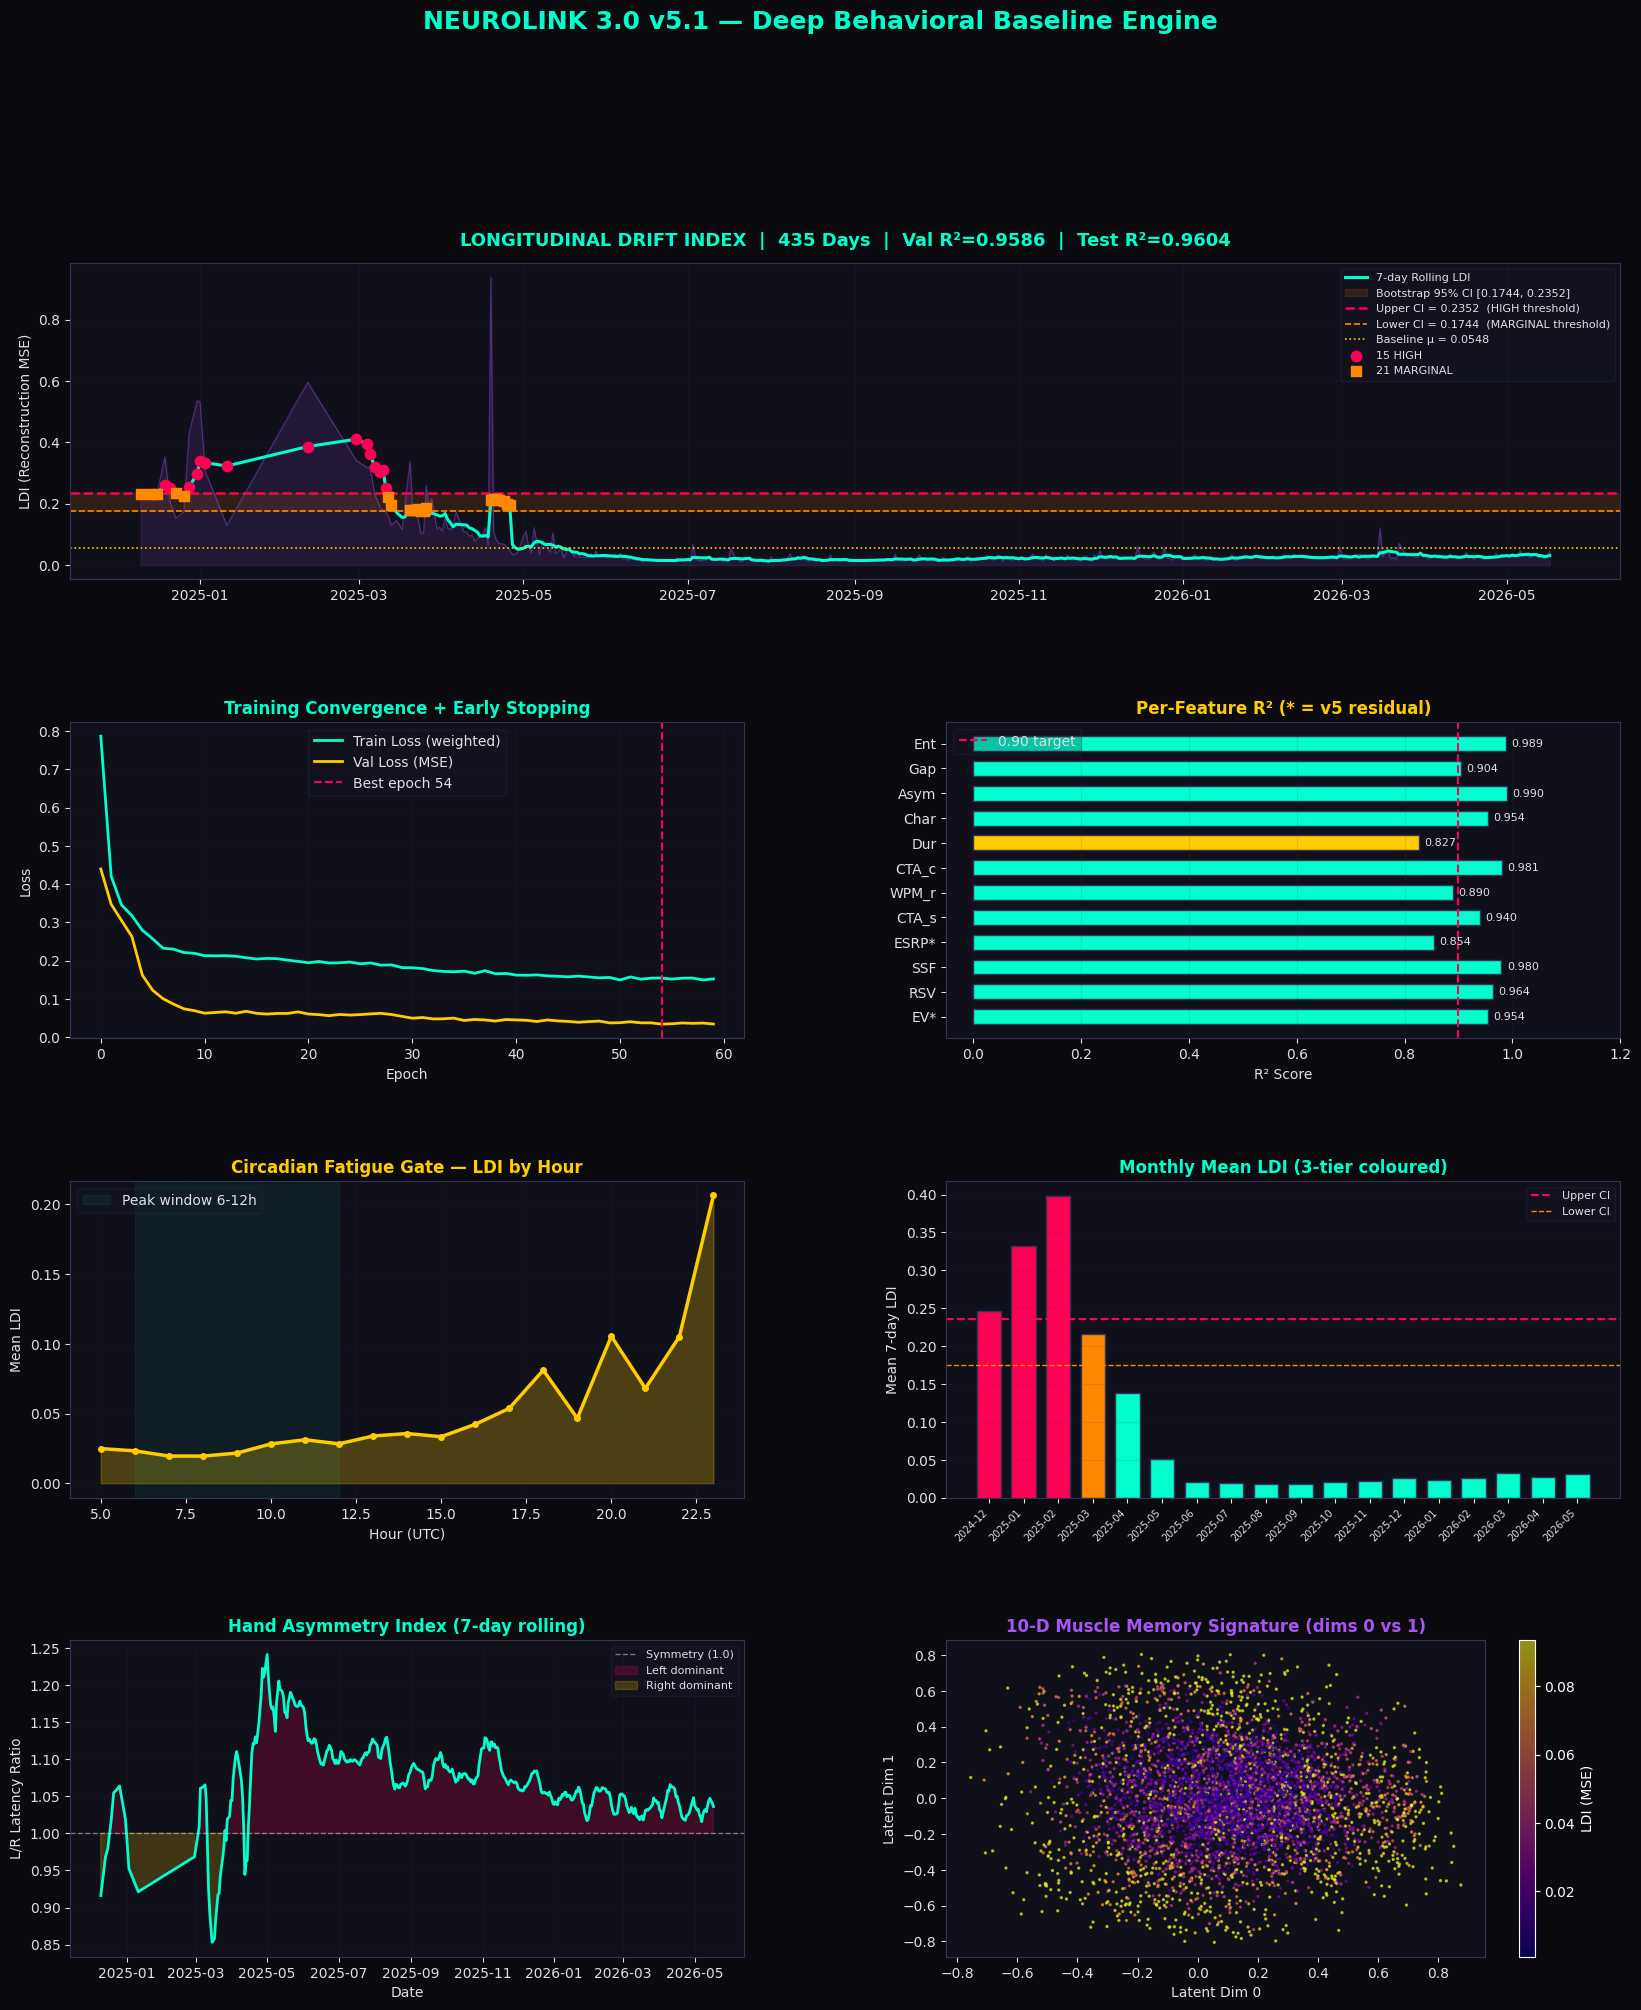

Dashboard saved -> neurolink_v5_1_dashboard.png


In [21]:
fig = plt.figure(figsize=(20, 22), facecolor='#0a0a0f')
gs  = gridspec.GridSpec(4, 2, figure=fig, hspace=0.45, wspace=0.3)

# ── Panel 1: LDI with 3-tier CI band ──────────────────────────────────────
ax1 = fig.add_subplot(gs[0, :])
ax1.set_facecolor('#10101a')
daily = daily_ldi.copy()
daily['date_dt'] = pd.to_datetime(daily['date'])

ax1.fill_between(daily['date_dt'], daily['LDI'], alpha=0.12, color=C_PURPLE)
ax1.plot(daily['date_dt'], daily['LDI'],    color=C_PURPLE, alpha=0.35, lw=0.8)
ax1.plot(daily['date_dt'], daily['LDI_7d'], color=C_CYAN,   lw=2.2, label='7-day Rolling LDI')

# CI band shading
ax1.axhspan(thresh_lo, thresh_hi, alpha=0.12, color=C_ORANGE, label=f'Bootstrap 95% CI [{thresh_lo:.4f}, {thresh_hi:.4f}]')
ax1.axhline(thresh_hi, color=C_MAGENTA, ls='--', lw=1.8, label=f'Upper CI = {thresh_hi:.4f}  (HIGH threshold)')
ax1.axhline(thresh_lo, color=C_ORANGE,  ls='--', lw=1.2, label=f'Lower CI = {thresh_lo:.4f}  (MARGINAL threshold)')
ax1.axhline(ldi_mean,  color=C_YELLOW,  ls=':',  lw=1.2, label=f'Baseline μ = {ldi_mean:.4f}')

# Scatter by tier
for tier, col, marker, label in [
    ('HIGH',     C_MAGENTA, 'o', f'{n_high} HIGH'),
    ('MARGINAL', C_ORANGE,  's', f'{n_marg} MARGINAL'),
]:
    sub = daily[daily['anomaly_tier']==tier]
    ax1.scatter(sub['date_dt'], sub['LDI_7d'], color=col, s=55, zorder=6,
                marker=marker, label=label)

ax1.set_title(f'LONGITUDINAL DRIFT INDEX  |  {len(daily)} Days  |  Val R²={r2_overall:.4f}  |  Test R²={r2_test:.4f}',
              color=C_CYAN, fontsize=13, pad=12, fontweight='bold')
ax1.set_ylabel('LDI (Reconstruction MSE)', color=C_WHITE)
ax1.tick_params(colors=C_WHITE)
for sp in ax1.spines.values(): sp.set_color('#333355')
ax1.legend(framealpha=0.25, facecolor='#1a1a2e', edgecolor='#333355', labelcolor=C_WHITE, fontsize=8)
ax1.grid(alpha=0.12, color='#333355')

# ── Panel 2: Training Convergence ─────────────────────────────────────────
ax2 = fig.add_subplot(gs[1, 0])
ax2.set_facecolor('#10101a')
ax2.plot(train_losses, color=C_CYAN,   lw=2, label='Train Loss (weighted)')
ax2.plot(val_losses,   color=C_YELLOW, lw=2, label='Val Loss (MSE)')
ax2.axvline(best_epoch, color=C_MAGENTA, ls='--', lw=1.5, label=f'Best epoch {best_epoch}')
ax2.set_title('Training Convergence + Early Stopping', color=C_CYAN, fontweight='bold')
ax2.set_xlabel('Epoch', color=C_WHITE); ax2.set_ylabel('Loss', color=C_WHITE)
ax2.tick_params(colors=C_WHITE); ax2.grid(alpha=0.12, color='#333355')
for sp in ax2.spines.values(): sp.set_color('#333355')
ax2.legend(framealpha=0.25, facecolor='#1a1a2e', edgecolor='#333355', labelcolor=C_WHITE)

# ── Panel 3: Per-feature R² ───────────────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 1])
ax3.set_facecolor('#10101a')
labels_short = ['EV*','RSV','SSF','ESRP*','CTA_s','WPM_r','CTA_c','Dur','Char','Asym','Gap','Ent']
r2_vals  = list(per_r2.values())
bar_cols = [C_CYAN if v>=0.85 else C_YELLOW if v>=0.50 else C_MAGENTA for v in r2_vals]
bars = ax3.barh(labels_short, r2_vals, color=bar_cols, edgecolor='#333355', height=0.6)
ax3.axvline(0.90, color=C_MAGENTA, ls='--', lw=1.5, label='0.90 target')
for bar, val in zip(bars, r2_vals):
    ax3.text(val+0.01, bar.get_y()+bar.get_height()/2, f'{val:.3f}',
             va='center', ha='left', color=C_WHITE, fontsize=8)
ax3.set_xlim(-0.05, 1.20)
ax3.set_title('Per-Feature R² (* = v5 residual)', color=C_YELLOW, fontweight='bold')
ax3.set_xlabel('R² Score', color=C_WHITE)
ax3.tick_params(colors=C_WHITE); ax3.grid(alpha=0.12, color='#333355', axis='x')
for sp in ax3.spines.values(): sp.set_color('#333355')
ax3.legend(framealpha=0.25, facecolor='#1a1a2e', edgecolor='#333355', labelcolor=C_WHITE)

# ── Panel 4: Circadian LDI ────────────────────────────────────────────────
ax4 = fig.add_subplot(gs[2, 0])
ax4.set_facecolor('#10101a')
hourly_ldi = pd.DataFrame({'hour': pd.to_datetime(eng.timestamps).dt.hour,
                            'LDI_raw': per_lesson_mse}).groupby('hour')['LDI_raw'].mean()
ax4.fill_between(hourly_ldi.index, hourly_ldi.values, alpha=0.25, color=C_YELLOW)
ax4.plot(hourly_ldi.index, hourly_ldi.values, color=C_YELLOW, lw=2.5, marker='o', ms=4)
ax4.axvspan(6, 12, alpha=0.06, color=C_CYAN, label='Peak window 6-12h')
ax4.set_title('Circadian Fatigue Gate — LDI by Hour', color=C_YELLOW, fontweight='bold')
ax4.set_xlabel('Hour (UTC)', color=C_WHITE); ax4.set_ylabel('Mean LDI', color=C_WHITE)
ax4.tick_params(colors=C_WHITE); ax4.grid(alpha=0.12, color='#333355')
for sp in ax4.spines.values(): sp.set_color('#333355')
ax4.legend(framealpha=0.25, facecolor='#1a1a2e', edgecolor='#333355', labelcolor=C_WHITE)

# ── Panel 5: Monthly LDI ──────────────────────────────────────────────────
ax5 = fig.add_subplot(gs[2, 1])
ax5.set_facecolor('#10101a')
daily_cp = daily.copy()
daily_cp['month'] = pd.to_datetime(daily_cp['date']).dt.to_period('M')
monthly  = daily_cp.groupby('month')['LDI_7d'].mean()
m_cols   = [C_MAGENTA if v>=thresh_hi else C_ORANGE if v>=thresh_lo else C_CYAN for v in monthly.values]
ax5.bar(range(len(monthly)), monthly.values, color=m_cols, edgecolor='#333355', width=0.7)
ax5.axhline(thresh_hi, color=C_MAGENTA, ls='--', lw=1.5, label='Upper CI')
ax5.axhline(thresh_lo, color=C_ORANGE,  ls='--', lw=1.0, label='Lower CI')
ax5.set_xticks(range(len(monthly)))
ax5.set_xticklabels([str(m) for m in monthly.index], rotation=45, ha='right', fontsize=7, color=C_WHITE)
ax5.set_title('Monthly Mean LDI (3-tier coloured)', color=C_CYAN, fontweight='bold')
ax5.set_ylabel('Mean 7-day LDI', color=C_WHITE)
ax5.tick_params(colors=C_WHITE); ax5.grid(alpha=0.12, color='#333355', axis='y')
for sp in ax5.spines.values(): sp.set_color('#333355')
ax5.legend(framealpha=0.25, facecolor='#1a1a2e', edgecolor='#333355', labelcolor=C_WHITE, fontsize=8)

# ── Panel 6: Hand Asymmetry ───────────────────────────────────────────────
ax6 = fig.add_subplot(gs[3, 0])
ax6.set_facecolor('#10101a')
asym_idx   = NeuroLink3Engine.FEATURE_COLS.index('hand_asymmetry')
asym_raw   = eng.features[:, asym_idx]
df_asym    = pd.DataFrame({'date': pd.to_datetime(eng.timestamps).dt.date, 'asym': asym_raw})
daily_asym = df_asym.groupby('date')['asym'].mean().reset_index()
daily_asym['date_dt'] = pd.to_datetime(daily_asym['date'])
daily_asym['asym_7d'] = daily_asym['asym'].rolling(7, min_periods=1).mean()
ax6.plot(daily_asym['date_dt'], daily_asym['asym_7d'], color=C_CYAN, lw=2)
ax6.axhline(1.0, color=C_WHITE, ls='--', lw=1, alpha=0.5, label='Symmetry (1.0)')
ax6.fill_between(daily_asym['date_dt'], daily_asym['asym_7d'], 1.0,
                 where=daily_asym['asym_7d']>1.0, alpha=0.2, color=C_MAGENTA, label='Left dominant')
ax6.fill_between(daily_asym['date_dt'], daily_asym['asym_7d'], 1.0,
                 where=daily_asym['asym_7d']<1.0, alpha=0.2, color=C_YELLOW, label='Right dominant')
ax6.set_title('Hand Asymmetry Index (7-day rolling)', color=C_CYAN, fontweight='bold')
ax6.set_xlabel('Date', color=C_WHITE); ax6.set_ylabel('L/R Latency Ratio', color=C_WHITE)
ax6.tick_params(colors=C_WHITE); ax6.grid(alpha=0.12, color='#333355')
for sp in ax6.spines.values(): sp.set_color('#333355')
ax6.legend(framealpha=0.25, facecolor='#1a1a2e', edgecolor='#333355', labelcolor=C_WHITE, fontsize=8)

# ── Panel 7: Latent Space ─────────────────────────────────────────────────
ax7 = fig.add_subplot(gs[3, 1])
ax7.set_facecolor('#10101a')
with torch.no_grad():
    latent_all = base_model.encode(X_full_t[:5000]).cpu().numpy()
sc = ax7.scatter(latent_all[:,0], latent_all[:,1],
                 c=per_lesson_mse[:5000], cmap='plasma', s=2, alpha=0.6,
                 vmax=np.percentile(per_lesson_mse, 95))
plt.colorbar(sc, ax=ax7, label='LDI (MSE)')
ax7.set_title('10-D Muscle Memory Signature (dims 0 vs 1)', color=C_PURPLE, fontweight='bold')
ax7.set_xlabel('Latent Dim 0', color=C_WHITE); ax7.set_ylabel('Latent Dim 1', color=C_WHITE)
ax7.tick_params(colors=C_WHITE)
for sp in ax7.spines.values(): sp.set_color('#333355')

fig.suptitle('NEUROLINK 3.0 v5.1 — Deep Behavioral Baseline Engine',
             fontsize=18, color=C_CYAN, fontweight='bold', y=0.995)
plt.savefig('neurolink_v5_1_dashboard.png', dpi=120, bbox_inches='tight', facecolor='#0a0a0f')
plt.show()
print("Dashboard saved -> neurolink_v5_1_dashboard.png")

## 9. Clinical Report & Model Save

In [22]:
print("="*68)
print("   NEUROLINK 3.0 v5.1  --  BEHAVIORAL BASELINE REPORT   ")
print("="*68)
print(f"  Validation R2 (variance-weighted)  : {r2_overall:.4f}  {'PASS' if r2_overall>=0.90 else 'FAIL'}")
print(f"  Test R2 (variance-weighted)        : {r2_test:.4f}")
print(f"  Best training epoch                : {best_epoch}  (val={best_val_loss:.5f})")
print(f"  DP budget                          : ε={final_epsilon:.4f}, δ={TARGET_DELTA}")
print("-"*68)
print("  ANOMALY DETECTION (3-tier bootstrap CI)")
print(f"  LDI μ={ldi_mean:.5f}  σ={ldi_std:.5f}")
print(f"  Bootstrap 95% CI   : [{thresh_lo:.5f}, {thresh_hi:.5f}]")
print(f"  HIGH anomaly days  : {n_high} / {len(daily_ldi)}  ({100*n_high/len(daily_ldi):.1f}%)")
print(f"  MARGINAL days      : {n_marg} / {len(daily_ldi)}  ({100*n_marg/len(daily_ldi):.1f}%)")
print("-"*68)
print("  CLINICAL DRIFT SIGNALS")
print(f"  Execution surprise (EV residual)   : R²={per_r2['EV']:.3f}")
print(f"  Error surprise (ESRP residual)     : R²={per_r2['ESRP']:.3f}")
print(f"  Motor jitter (RSV)                 : R²={per_r2['RSV']:.3f}")
print(f"  Motor asymmetry (hand_asymmetry)   : R²={per_r2['hand_asymmetry']:.3f}")
print(f"  Error locality (error_entropy)     : R²={per_r2['error_entropy']:.3f}")
print("="*68)

torch.save({
    'model_state_dict':  base_model.state_dict(),
    'r2_val':            r2_overall,
    'r2_test':           r2_test,
    'ldi_mean':          ldi_mean,
    'ldi_std':           ldi_std,
    'anomaly_threshold': anomaly_threshold,
    'thresh_lo':         thresh_lo,
    'thresh_hi':         thresh_hi,
    'best_epoch':        best_epoch,
    'per_feature_r2':    per_r2,
    'feature_cols':      NeuroLink3Engine.FEATURE_COLS,
    'seed':              SEED,
}, 'neurolink_v5_1_model.pt')
print("Model saved -> neurolink_v5_1_model.pt")

   NEUROLINK 3.0 v5.1  --  BEHAVIORAL BASELINE REPORT   
  Validation R2 (variance-weighted)  : 0.9586  PASS
  Test R2 (variance-weighted)        : 0.9604
  Best training epoch                : 54  (val=0.03378)
  DP budget                          : ε=7.9983, δ=1e-05
--------------------------------------------------------------------
  ANOMALY DETECTION (3-tier bootstrap CI)
  LDI μ=0.05480  σ=0.07583
  Bootstrap 95% CI   : [0.17443, 0.23522]
  HIGH anomaly days  : 15 / 435  (3.4%)
  MARGINAL days      : 21 / 435  (4.8%)
--------------------------------------------------------------------
  CLINICAL DRIFT SIGNALS
  Execution surprise (EV residual)   : R²=0.954
  Error surprise (ESRP residual)     : R²=0.854
  Motor jitter (RSV)                 : R²=0.964
  Motor asymmetry (hand_asymmetry)   : R²=0.990
  Error locality (error_entropy)     : R²=0.989
Model saved -> neurolink_v5_1_model.pt


## 10. Ghost V3 — Empirically Calibrated

### v5 upgrade: data-derived scale factor

The `0.05` scale factor in previous versions was a guess.
We now derive it from the linear relationship between daily LDI ratio and actual WPM
across all 42,501 lessons — fitting `mean_daily_wpm = a + b × ldi_ratio`
and extracting the fractional WPM change per unit drift.

Ghost V3 — Empirical Calibration
  Linear fit  : WPM = 91.55 + (-13.5650) × ldi_ratio
  Correlation : r = -0.6979
  Mean WPM    : 79.09
  Empirical scale factor : 0.1500
  Previous guess         : 0.0500
  Difference             : 10.0%

   NEUROLINK 3.0 v5: GHOST V3 PREDICTION   
  text                   : Lazy practice performance dog lazy performance performance fox dog brown.
  ghost_v2_time          : 8.49
  ghost_v3_time          : 7.93
  ldi_adjustment         : -6.56%
  current_ldi            : 0.03082
  baseline_ldi           : 0.0548
  empirical_scale        : 0.15


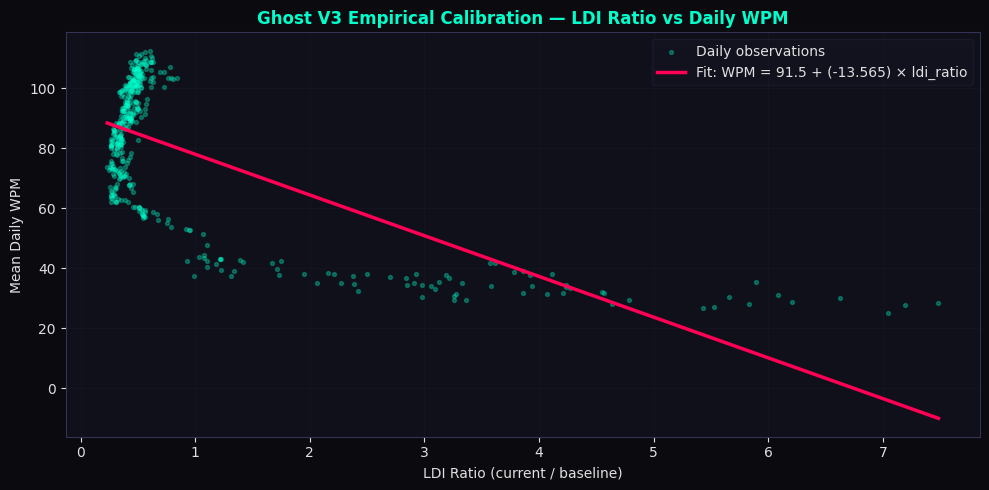

Calibration plot saved -> ghost_v3_calibration.png


In [23]:
# ── UPGRADE 3: Empirical Ghost V3 calibration ─────────────────────────────
df_wpm_daily = (pd.DataFrame({'date': pd.to_datetime(eng.timestamps).dt.date,
                               'wpm':  eng.wpm})
                .groupby('date')['wpm'].mean()
                .reset_index())

df_calib = daily_ldi[['date','LDI_7d']].merge(df_wpm_daily, on='date')
df_calib['ldi_ratio'] = df_calib['LDI_7d'] / max(ldi_mean, 1e-8)

# Linear fit: WPM = a + b × ldi_ratio   (expect b < 0)
z_fit      = np.polyfit(df_calib['ldi_ratio'], df_calib['wpm'], 1)
slope, intercept = float(z_fit[0]), float(z_fit[1])
mean_wpm_calib   = float(df_calib['wpm'].mean())

# scale_factor = -slope / mean_wpm  (positive; higher LDI → slower → more time)
empirical_scale = float(-slope / mean_wpm_calib)
empirical_scale = float(np.clip(empirical_scale, 0.01, 0.15))  # sane range

print(f"Ghost V3 — Empirical Calibration")
print(f"  Linear fit  : WPM = {intercept:.2f} + ({slope:.4f}) × ldi_ratio")
print(f"  Correlation : r = {np.corrcoef(df_calib['ldi_ratio'], df_calib['wpm'])[0,1]:.4f}")
print(f"  Mean WPM    : {mean_wpm_calib:.2f}")
print(f"  Empirical scale factor : {empirical_scale:.4f}")
print(f"  Previous guess         : 0.0500")
print(f"  Difference             : {abs(empirical_scale-0.05)*100:.1f}%")
print()

def ghost_v3(text, scale=empirical_scale):
    recent_wpm    = eng.wpm[-500:].mean()
    error_penalty = eng.get_v2_error_penalty()
    chars_per_sec = (recent_wpm * 5) / 60
    base_time     = len(text) / chars_per_sec
    sim_errors    = round(len(text) * 0.01)
    ghost_v2_time = round(base_time + sim_errors * (error_penalty / 10), 2)

    current_ldi  = daily_ldi['LDI_7d'].iloc[-1]
    ldi_ratio    = current_ldi / max(ldi_mean, 1e-8)
    ldi_factor   = (ldi_ratio - 1) * scale   # signed: negative = speed bonus
    ghost_v3_time = round(ghost_v2_time * (1 + ldi_factor), 2)

    return {
        'text':              text,
        'ghost_v2_time':     ghost_v2_time,
        'ghost_v3_time':     ghost_v3_time,
        'ldi_adjustment':    f'{ldi_factor*100:+.2f}%',
        'current_ldi':       round(float(current_ldi), 5),
        'baseline_ldi':      round(ldi_mean, 5),
        'empirical_scale':   round(empirical_scale, 4),
    }

words = ["the","quick","brown","fox","jumps","over","lazy","dog",
         "neural","typing","performance","analysis","speed","accuracy",
         "practice","focus","consistency","control"]
practice = (" ".join(np.random.choice(words, 10))).capitalize() + "."
result = ghost_v3(practice)
print("="*52)
print("   NEUROLINK 3.0 v5: GHOST V3 PREDICTION   ")
print("="*52)
for k, v in result.items():
    print(f"  {k:<22} : {v}")
print("="*52)

# ── Calibration scatter plot ──────────────────────────────────────────────
fig3, ax = plt.subplots(figsize=(10, 5), facecolor='#0a0a0f')
ax.set_facecolor('#10101a')
ax.scatter(df_calib['ldi_ratio'], df_calib['wpm'], alpha=0.3, s=8,
           color=C_CYAN, label='Daily observations')
x_line = np.linspace(df_calib['ldi_ratio'].min(), df_calib['ldi_ratio'].max(), 100)
ax.plot(x_line, intercept + slope*x_line, color=C_MAGENTA, lw=2.5,
        label=f'Fit: WPM = {intercept:.1f} + ({slope:.3f}) × ldi_ratio')
ax.set_title('Ghost V3 Empirical Calibration — LDI Ratio vs Daily WPM',
             color=C_CYAN, fontweight='bold')
ax.set_xlabel('LDI Ratio (current / baseline)', color=C_WHITE)
ax.set_ylabel('Mean Daily WPM', color=C_WHITE)
ax.tick_params(colors=C_WHITE)
ax.legend(framealpha=0.25, facecolor='#1a1a2e', edgecolor='#333355', labelcolor=C_WHITE)
ax.grid(alpha=0.12, color='#333355')
for sp in ax.spines.values(): sp.set_color('#333355')
plt.tight_layout()
plt.savefig('ghost_v3_calibration.png', dpi=120, bbox_inches='tight', facecolor='#0a0a0f')
plt.show()
print("Calibration plot saved -> ghost_v3_calibration.png")

## 11. Real-Time Inference Engine

`NeuroLinkInference` now returns a **3-tier alert** (HIGH / MARGINAL / NORMAL)
using the bootstrap CI thresholds instead of a binary flag.

In [24]:
class NeuroLinkInference:
    """Real-time inference — 3-tier alerting (HIGH / MARGINAL / NORMAL)."""
    def __init__(self, model, scaler, feature_cols,
                 ldi_mean, thresh_lo, thresh_hi, device):
        self.model        = model
        self.scaler       = scaler
        self.feature_cols = feature_cols
        self.ldi_mean     = ldi_mean
        self.thresh_lo    = thresh_lo
        self.thresh_hi    = thresh_hi
        self.device       = device
        self.history      = []

    def infer_lesson(self, raw_features: np.ndarray) -> dict:
        x_scaled = self.scaler.transform(raw_features.reshape(1,-1))
        x_scaled = np.clip(x_scaled, -4, 4).astype(np.float32)
        x_t      = torch.tensor(x_scaled, dtype=torch.float32).to(self.device)

        self.model.eval()
        with torch.no_grad():
            recon    = self.model(x_t)
            feat_mse = ((x_t - recon)**2).cpu().numpy()[0]
            total_mse = float(feat_mse.mean())

        self.history.append(total_mse)
        rolling_ldi = float(np.mean(self.history[-7:]))

        if   rolling_ldi >= self.thresh_hi: alert = 'HIGH'
        elif rolling_ldi >= self.thresh_lo: alert = 'MARGINAL'
        else:                               alert = 'NORMAL'

        total_feat = feat_mse.sum() + 1e-12
        top_drivers = sorted(
            zip(self.feature_cols, feat_mse), key=lambda x:-x[1])[:3]

        return {
            'reconstruction_mse': round(total_mse, 6),
            'rolling_ldi_7':      round(rolling_ldi, 6),
            'alert_tier':         alert,
            'top_drivers':        [(c, round(100*m/total_feat,1)) for c,m in top_drivers],
        }


inference_engine = NeuroLinkInference(
    model=base_model, scaler=scaler,
    feature_cols=NeuroLink3Engine.FEATURE_COLS,
    ldi_mean=ldi_mean, thresh_lo=thresh_lo, thresh_hi=thresh_hi,
    device=device,
)

print("Real-time inference demo — last 10 lessons:")
print("-"*65)
for i in range(-10, 0):
    r = inference_engine.infer_lesson(eng.features[i])
    tier_col = {'HIGH':'🔴','MARGINAL':'🟡','NORMAL':'🟢'}.get(r['alert_tier'],'')
    drivers  = '  |  '.join(f"{d[0]} {d[1]:.0f}%" for d in r['top_drivers'])
    print(f"  Lesson {i:3d}  MSE={r['reconstruction_mse']:.5f}  "
          f"{tier_col} {r['alert_tier']:<8}")
    print(f"           Top drivers: {drivers}")
print("-"*65)
print("\nTo use in production:")
print("  r = inference_engine.infer_lesson(feature_array)")
print("  if r['alert_tier'] == 'HIGH': send_alert()")

Real-time inference demo — last 10 lessons:
-----------------------------------------------------------------
  Lesson -10  MSE=0.05620  🟢 NORMAL  
           Top drivers: EV 32%  |  CTA_cos 23%  |  wpm_vs_50roll 21%
  Lesson  -9  MSE=0.03651  🟢 NORMAL  
           Top drivers: EV 44%  |  hand_asymmetry 16%  |  error_entropy 15%
  Lesson  -8  MSE=0.03323  🟢 NORMAL  
           Top drivers: ESRP 36%  |  EV 22%  |  CTA 13%
  Lesson  -7  MSE=0.01027  🟢 NORMAL  
           Top drivers: ESRP 34%  |  CTA 21%  |  EV 12%
  Lesson  -6  MSE=0.11353  🟢 NORMAL  
           Top drivers: active_char_frac 38%  |  SSF 18%  |  error_entropy 18%
  Lesson  -5  MSE=0.01874  🟢 NORMAL  
           Top drivers: ESRP 50%  |  CTA 30%  |  CTA_cos 6%
  Lesson  -4  MSE=0.01077  🟢 NORMAL  
           Top drivers: CTA 48%  |  ESRP 35%  |  wpm_vs_50roll 8%
  Lesson  -3  MSE=0.06937  🟢 NORMAL  
           Top drivers: wpm_vs_50roll 32%  |  EV 28%  |  ESRP 17%
  Lesson  -2  MSE=0.10392  🟢 NORMAL  
           Top drive

## 12. Sliding 90-Day Adaptive Baseline

Prevents stale thresholds after genuine long-term improvement.
The adaptive baseline uses the lower 75th percentile of each 90-day window
to exclude anomaly spikes from polluting the new baseline estimate.

Fixed threshold   :  15 HIGH + 21 MARGINAL anomaly days
Adaptive baseline : 121 anomaly days  (27.8%)


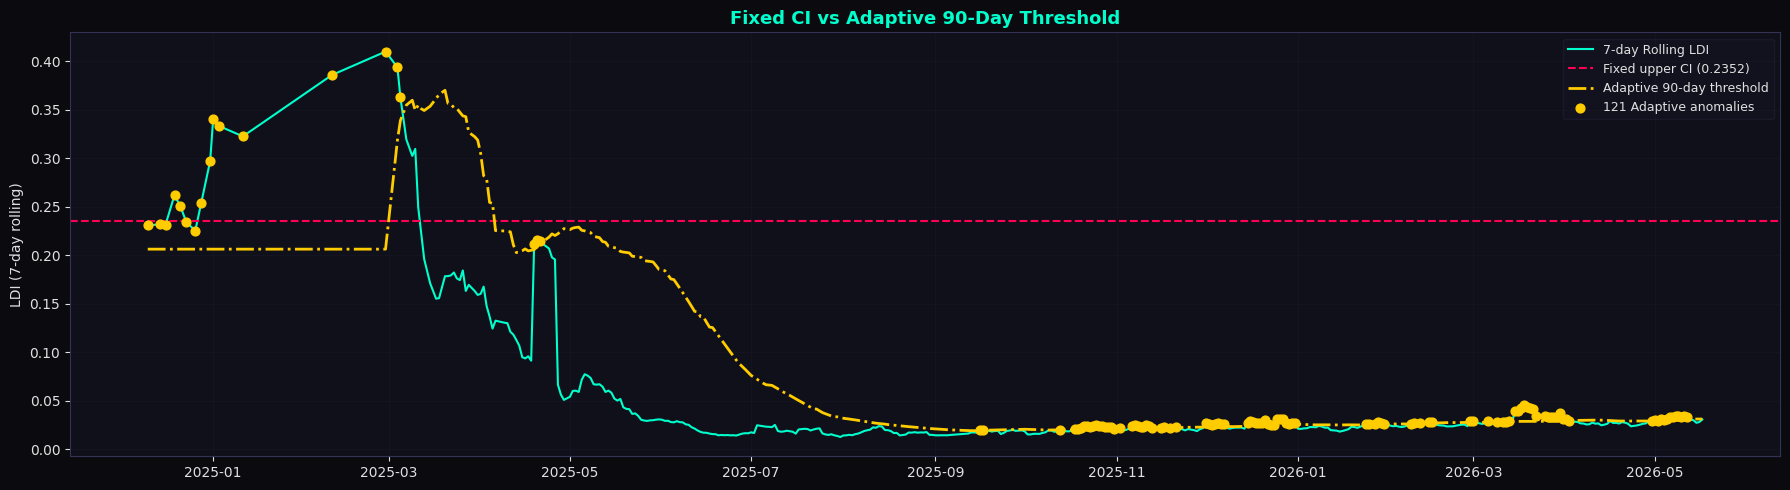

Adaptive baseline plot saved -> neurolink_v5_adaptive.png


In [25]:
def compute_adaptive_baseline(daily_ldi_df, window_days=90, min_stable_days=14):
    df = daily_ldi_df.copy()
    df['date_dt'] = pd.to_datetime(df['date'])
    df = df.sort_values('date_dt').reset_index(drop=True)
    am, as_, at_ = [], [], []
    for i, row in df.iterrows():
        cutoff = row['date_dt'] - pd.Timedelta(days=window_days)
        window = df[(df['date_dt']>=cutoff) & (df.index<i)]['LDI_7d']
        if len(window) < min_stable_days:
            am.append(ldi_mean); as_.append(ldi_std); at_.append(anomaly_threshold)
        else:
            stable = window[window <= window.quantile(0.75)]
            mu     = float(stable.mean())
            sigma  = float(stable.std()) if len(stable)>1 else ldi_std
            am.append(mu); as_.append(sigma); at_.append(mu + 2*sigma)
    df['adaptive_mean'] = am; df['adaptive_std'] = as_
    df['adaptive_threshold'] = at_
    df['adaptive_anomaly'] = df['LDI_7d'] > df['adaptive_threshold']
    return df


adaptive_ldi = compute_adaptive_baseline(daily_ldi, window_days=90)
n_adaptive = int(adaptive_ldi['adaptive_anomaly'].sum())

print(f"Fixed threshold   : {n_high:3d} HIGH + {n_marg} MARGINAL anomaly days")
print(f"Adaptive baseline : {n_adaptive:3d} anomaly days  ({100*n_adaptive/len(adaptive_ldi):.1f}%)")

fig4, ax = plt.subplots(figsize=(18, 5), facecolor='#0a0a0f')
ax.set_facecolor('#10101a')
adaptive_ldi['date_dt'] = pd.to_datetime(adaptive_ldi['date'])
ax.plot(adaptive_ldi['date_dt'], adaptive_ldi['LDI_7d'],
        color=C_CYAN, lw=1.5, label='7-day Rolling LDI')
ax.axhline(thresh_hi, color=C_MAGENTA, ls='--', lw=1.5,
           label=f'Fixed upper CI ({thresh_hi:.4f})')
ax.plot(adaptive_ldi['date_dt'], adaptive_ldi['adaptive_threshold'],
        color=C_YELLOW, lw=2, ls='-.', label='Adaptive 90-day threshold')
anom_adapt = adaptive_ldi[adaptive_ldi['adaptive_anomaly']]
ax.scatter(anom_adapt['date_dt'], anom_adapt['LDI_7d'],
           color=C_YELLOW, s=40, zorder=6, label=f'{n_adaptive} Adaptive anomalies')
ax.set_title('Fixed CI vs Adaptive 90-Day Threshold', color=C_CYAN, fontsize=13, fontweight='bold')
ax.set_ylabel('LDI (7-day rolling)', color=C_WHITE)
ax.tick_params(colors=C_WHITE)
ax.legend(framealpha=0.25, facecolor='#1a1a2e', edgecolor='#333355', labelcolor=C_WHITE, fontsize=9)
ax.grid(alpha=0.12, color='#333355')
for sp in ax.spines.values(): sp.set_color('#333355')
plt.tight_layout()
plt.savefig('neurolink_v5_adaptive.png', dpi=120, bbox_inches='tight', facecolor='#0a0a0f')
plt.show()
print("Adaptive baseline plot saved -> neurolink_v5_adaptive.png")